# Аналитика продаж и покупателей

## 1. Измеряемые события и группировка

Каждая строка исходной таблицы означает один оформленный заказ, а статус описывает его дальнейшую судьбу. Поэтому количество всех оформленных заказов и сумма их стоимости не имеют того же смысла, что количество и стоимость доставленных. Сумма `amount` по статусу delivered остаётся стоимостью доставленных заказов в этом наборе; финансовых сведений для бухгалтерского понятия выручки здесь нет. Вначале для каждого расчёта определяется наблюдаемая совокупность, затем рассматриваются группировки строк и корректные знаменатели долей. Данные синтетические, поэтому их динамика служит учебным примером, а не доказательством реальной сезонности.

**Автономная загрузка таблиц**

Ноутбук читает исходные CSV сам и не зависит от переменных предыдущего занятия. Каталог `data` ищется от рабочего каталога вверх по родителям: в учебной структуре он расположен рядом с `practice`. Даты преобразуются при чтении, иначе месячная группировка работала бы со строками, а не с календарём. Размеры таблиц и крайние даты задают окно наблюдения. У заказов единица наблюдения — строка, но перед подсчётом числа заказов всё равно следует убедиться в уникальности идентификаторов. Справочники покупателей и товаров понадобятся только там, где их поля добавляют смысл к заказу.

In [1]:
# Шаг 02.01 — Автономная загрузка таблиц
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

DATA_DIR = next((p / 'data' for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'data' / 'orders.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Каталог data с orders.csv не найден')
orders = pd.read_csv(DATA_DIR / 'orders.csv', parse_dates=['order_ts'])
customers = pd.read_csv(DATA_DIR / 'customers.csv', parse_dates=['registered'])
products = pd.read_csv(DATA_DIR / 'products.csv')
print('Заказы:', orders.shape, 'Покупатели:', customers.shape, 'Товары:', products.shape)
print('Период:', orders.order_ts.min(), '—', orders.order_ts.max())
display(orders.head(3))

Заказы: (200000, 10) Покупатели: (20000, 4) Товары: (2000, 4)
Период: 2026-01-01 00:00:19 — 2026-12-31 23:58:45


,order_id,order_ts,customer_id,city,product_id,category,qty,price,amount,status
0,1,2026-01-17 08:50:04,8384,Санкт-Петербург,1104,Одежда,1,9700,9700,delivered
1,2,2026-07-13 14:51:05,11971,Краснодар,1471,Продукты,1,480,480,delivered
2,3,2026-11-03 13:42:32,19274,Новосибирск,887,Обувь,1,7630,7630,delivered


**Статусы и доли количества**

`value_counts` считает частоты категориального поля. Здесь частота статуса — число строк заказов, а не денежная сумма. Знаменатель доли статуса — все оформленные заказы. Проверка `nunique` идентификатора показывает, совпадает ли количество строк с числом заказов; если бы строки представляли позиции заказа, считать строки было бы неверно. Четыре статуса нельзя бездумно объединять в одну меру «продаж». В частности, отменённый заказ мог иметь стоимость при оформлении, но это не означает полученные деньги. Следующий шаг явно создаст подмножество delivered.

In [2]:
# Шаг 02.02 — Статусы и доли количества
counts = orders.status.value_counts().rename('orders')
shares = (counts / len(orders) * 100).rename('share_pct')
display(pd.concat([counts, shares], axis=1).round(2))
print('Уникальных заказов:', orders.order_id.nunique(), 'строк:', len(orders))

,orders,share_pct
status,,
delivered,164061,82.03
cancelled,17980,8.99
returned,10045,5.02
in_transit,7914,3.96


Уникальных заказов: 200000 строк: 200000


**Две денежные суммы и средний заказ**

Сумма `amount` по всем исходным строкам — стоимость всех оформленных заказов, включая отменённые и возвращённые. Сумма по delivered — стоимость доставленных заказов. Средний доставленный заказ делит вторую сумму на количество доставленных заказов. Денежная доля delivered использует денежный знаменатель — стоимость всех оформленных заказов; она не обязана совпасть с долей доставленных по числу заказов. Набор не описывает платежи, налоги, комиссии и возвраты денег, поэтому термин «бухгалтерская выручка» для полученной суммы был бы необоснованным.

In [3]:
# Шаг 02.03 — Две денежные суммы и средний заказ
delivered = orders.loc[orders.status.eq('delivered')].copy()
all_amount = orders.amount.sum()
delivered_amount = delivered.amount.sum()
display(pd.Series({'Оформлено заказов': len(orders),
                   'Стоимость оформленных': all_amount,
                   'Доставлено заказов': len(delivered),
                   'Стоимость доставленных': delivered_amount,
                   'Средний доставленный заказ': delivered.amount.mean(),
                   'Доля доставленных в стоимости оформленных, %':
                       delivered_amount / all_amount * 100}).round(2))

Оформлено заказов                               2.000000e+05
Стоимость оформленных                           6.266420e+09
Доставлено заказов                              1.640610e+05
Стоимость доставленных                          5.135477e+09
Средний доставленный заказ                      3.130224e+04
Доля доставленных в стоимости оформленных, %    8.195000e+01
dtype: float64

**Несколько агрегатов по статусу**

`groupby` разбивает строки на группы, а `agg` сворачивает каждую группу в одну строку результата. Именованные агрегаты задают понятные заголовки: количество, сумму, среднее и медиану. Среднее чувствительно к дорогим заказам, медиана описывает центральное наблюдение упорядоченной группы. Сумма по cancelled означает стоимость оформленных заказов, которые потом отменили; она не становится полученной выручкой. Наличие нескольких мер рядом помогает отделить масштаб группы от типичного размера заказа. `size` здесь уместен, поскольку идентификаторы заказов уникальны.

In [4]:
# Шаг 02.04 — Несколько агрегатов по статусу
by_status = (orders.groupby('status')
             .agg(orders=('order_id', 'size'), amount=('amount', 'sum'),
                  mean_amount=('amount', 'mean'), median_amount=('amount', 'median'))
             .sort_values('orders', ascending=False))
display(by_status.round(2))

,orders,amount,mean_amount,median_amount
status,,,,
delivered,164061,5135476730,31302.24,10360.0
cancelled,17980,565172220,31433.38,10580.0
returned,10045,318262720,31683.70,10800.0
in_transit,7914,247507870,31274.69,10475.0


**Transform и доля доставки внутри категории**

`transform` возвращает результат той же длины, что исходная таблица, повторяя групповое значение в строках этой группы. Это удобно для построчных долей или отклонений от групповой нормы. Здесь размер категории вычисляется на всех оформленных заказах. Далее булев индикатор доставки агрегируется по категории: сумма даёт числитель, среднее даёт долю, потому что `True` считается единицей, а `False` нулём. Знаменатель процента — все оформленные заказы соответствующей категории, а не общая сумма заказов. Количество строк рядом с процентом показывает масштаб группы.

In [5]:
# Шаг 02.05 — Transform и доля доставки внутри категории
category_rows = orders.assign(
    category_total=orders.groupby('category').order_id.transform('size'),
    is_delivered=orders.status.eq('delivered'))
category_delivery = (category_rows.groupby('category')
    .agg(all_orders=('order_id', 'size'),
         delivered_orders=('is_delivered', 'sum'),
         delivered_share=('is_delivered', 'mean')))
category_delivery['delivered_share_pct'] = category_delivery.delivered_share * 100
display(category_delivery[['all_orders', 'delivered_orders', 'delivered_share_pct']].round(2))
print('Размер группы постоянен внутри категории:',
      category_rows.groupby('category').category_total.nunique().eq(1).all())

,all_orders,delivered_orders,delivered_share_pct
category,,,
Бытовая техника,19841,16206,81.68
Дом и сад,11754,9725,82.74
Книги,15389,12609,81.94
Красота,13623,11247,82.56
Обувь,19764,16210,82.02
Одежда,40561,33154,81.74
Продукты,31008,25509,82.27
Спорт,11654,9530,81.77
Электроника,36406,29871,82.05


Размер группы постоянен внутри категории: True


**Выводы раздела**

Количество оформленных заказов, стоимость всех оформленных и стоимость доставленных заказов теперь имеют разные точные названия. В этом файле 200 000 заказов, из них 164 061 получили статус delivered. Эти числа не превращают стоимость delivered в бухгалтерскую выручку: платёжной таблицы и правил финансового учёта в наборе нет. Если позднее строится доля, сначала следует спросить, относится ли её числитель к числу заказов, к их стоимости или к числу людей. Затем нужно проверить, что знаменатель использует ту же единицу и нужную популяцию. `groupby` и `transform` делают такие расчёты удобными, но смысл результата определяет аналитический вопрос. Этот порядок действий переносится на любые таблицы заказов, даже когда названия статусов и категорий другие.

## 2. Категории, города и сегменты

Категория описывает товар, город описывает место заказа, сегмент приходит из справочника покупателей. Абсолютный объём и относительная доля отвечают на разные вопросы: первая показывает масштаб, вторая структуру. Два измерения можно совместить в кросс-таблице или сводной таблице, но ячейки таких таблиц могут означать число заказов, денежную стоимость либо процент. Подпись и знаменатель сохраняют значение даже при одинаковой форме таблиц.

**Доли категорий в стоимости доставленных**

Сначала отбираются доставленные заказы, затем вычисляются количество, сумма и средний заказ по категории. Денежная доля категории делит её сумму на общую стоимость доставленных заказов. Если категории исчерпывают доставленную выборку и каждая строка относится к одной категории, сумма процентов должна быть равна ста. Количество заказов нужно показать рядом с денежной суммой: высокая доля стоимости может возникать либо из-за частых покупок, либо из-за высокой стоимости одного заказа. Проверка суммы долей служит проверкой выбранного знаменателя.

In [6]:
# Шаг 02.06 — Доли категорий в стоимости доставленных
category_value = (delivered.groupby('category')
    .agg(orders=('order_id', 'size'), amount=('amount', 'sum'),
         mean_order=('amount', 'mean')).sort_values('amount', ascending=False))
category_value['share_pct'] = category_value.amount / delivered_amount * 100
display(category_value.round(2))
print('Сумма долей, %:', round(category_value.share_pct.sum(), 6))

,orders,amount,mean_order,share_pct
category,,,,
Электроника,29871,2828217760,94681.05,55.07
Бытовая техника,16206,1088000570,67135.66,21.19
Одежда,33154,369798710,11153.97,7.20
Спорт,9530,265918780,27903.33,5.18
Обувь,16210,239106470,14750.55,4.66
Дом и сад,9725,188890030,19423.14,3.68
Красота,11247,67795050,6027.83,1.32
Продукты,25509,59220960,2321.57,1.15
Книги,12609,28528400,2262.54,0.56


Сумма долей, %: 100.0


**Частоты категорий и городов**

`value_counts` быстро подсчитывает частоты одного категориального столбца. В delivered-выборке частота категории — число заказов этой категории, частота города — число доставленных заказов с указанным городом в записи. Ни одна из этих таблиц не даёт числа уникальных покупателей: человек может сделать несколько заказов. Для количества проданных единиц нужно суммировать `qty`, а для числа покупателей — считать `nunique` по `customer_id`. Слово «популярность» слишком расплывчато без уточнения выбранной меры.

In [7]:
# Шаг 02.07 — Частоты категорий и городов
print('Категории:')
display(delivered.category.value_counts().rename('orders').to_frame())
print('Города:')
display(delivered.city.value_counts().rename('orders').to_frame())

Категории:


,orders
category,
Одежда,33154
Электроника,29871
Продукты,25509
Обувь,16210
Бытовая техника,16206
Книги,12609
Красота,11247
Дом и сад,9725
Спорт,9530


Города:


,orders
city,
Москва,66516
Новосибирск,17846
Санкт-Петербург,15918
Казань,6317
Екатеринбург,6195
Самара,6067
Красноярск,5881
Краснодар,5834
Тюмень,5636


**Crosstab городов и категорий**

`crosstab` считает совместные частоты двух признаков. Ячейка здесь — число delivered-заказов соответствующего города и категории. Итог строки относится ко всем категориям города, итог столбца — ко всем городам категории. Общая итоговая ячейка обязана равняться длине delivered-выборки. Это таблица абсолютных частот. Крупный город может иметь много заказов в каждой категории просто из-за своего размера, поэтому относительную структуру следует анализировать отдельной нормировкой.

In [8]:
# Шаг 02.08 — Crosstab городов и категорий
city_category_count = pd.crosstab(delivered.city, delivered.category,
                                  margins=True, margins_name='Итого')
display(city_category_count)
print('Итог:', city_category_count.loc['Итого', 'Итого'],
      'доставленных строк:', len(delivered))

category,Бытовая техника,Дом и сад,Книги,Красота,Обувь,Одежда,Продукты,Спорт,Электроника,Итого
city,,,,,,,,,,
Волгоград,400,232,283,217,373,733,596,213,693,3740
Воронеж,337,198,234,209,279,620,498,176,563,3114
Екатеринбург,623,385,482,413,649,1222,977,349,1095,6195
Казань,618,378,479,437,614,1267,1001,348,1175,6317
Краснодар,585,353,439,389,558,1174,939,327,1070,5834
Красноярск,552,346,437,375,540,1255,907,347,1122,5881
Москва,6586,3892,5178,4598,6611,13417,10268,3924,12042,66516
Нижний Новгород,370,234,299,281,404,840,595,216,726,3965
Новосибирск,1833,1055,1343,1232,1727,3587,2748,1017,3304,17846


Итог: 164061 доставленных строк: 164061


**Нормировка внутри города**

Параметр `normalize='index'` делит каждую ячейку кросс-таблицы на сумму соответствующей строки. Поэтому после умножения на сто каждая городская строка суммируется в сто процентов. Ячейка означает долю категории среди доставленных заказов именно этого города. Проценты снимают эффект разного объёма городских заказов, но не объясняют причины различий. Для оценки надёжности сопоставления полезно держать рядом абсолютные итоги предыдущей таблицы.

In [9]:
# Шаг 02.09 — Нормировка внутри города
city_category_pct = pd.crosstab(delivered.city, delivered.category,
                                normalize='index') * 100
display(city_category_pct.round(2))
print('Суммы строк, %:', city_category_pct.sum(axis=1).round(6).to_dict())

category,Бытовая техника,Дом и сад,Книги,Красота,Обувь,Одежда,Продукты,Спорт,Электроника
city,,,,,,,,,
Волгоград,10.70,6.20,7.57,5.80,9.97,19.60,15.94,5.70,18.53
Воронеж,10.82,6.36,7.51,6.71,8.96,19.91,15.99,5.65,18.08
Екатеринбург,10.06,6.21,7.78,6.67,10.48,19.73,15.77,5.63,17.68
Казань,9.78,5.98,7.58,6.92,9.72,20.06,15.85,5.51,18.60
Краснодар,10.03,6.05,7.52,6.67,9.56,20.12,16.10,5.61,18.34
Красноярск,9.39,5.88,7.43,6.38,9.18,21.34,15.42,5.90,19.08
Москва,9.90,5.85,7.78,6.91,9.94,20.17,15.44,5.90,18.10
Нижний Новгород,9.33,5.90,7.54,7.09,10.19,21.19,15.01,5.45,18.31
Новосибирск,10.27,5.91,7.53,6.90,9.68,20.10,15.40,5.70,18.51


Суммы строк, %: {'Волгоград': 100.0, 'Воронеж': 100.0, 'Екатеринбург': 100.0, 'Казань': 100.0, 'Краснодар': 100.0, 'Красноярск': 100.0, 'Москва': 100.0, 'Нижний Новгород': 100.0, 'Новосибирск': 100.0, 'Омск': 100.0, 'Пермь': 100.0, 'Ростов-на-Дону': 100.0, 'Самара': 100.0, 'Санкт-Петербург': 100.0, 'Тюмень': 100.0, 'Уфа': 100.0}


**Pivot table для денежных сумм**

`pivot_table` строит матрицу по двум измерениям и агрегирует выбранную числовую меру. Здесь явно указаны `values='amount'` и `aggfunc='sum'`, поэтому ячейка означает стоимость доставленных заказов города и категории. `fill_value=0` обозначает наблюдаемое сочетание без заказов. Общая итоговая ячейка должна равняться общей сумме delivered. Визуально похожая кросс-таблица предыдущего шага содержала количество заказов; форма матрицы не определяет смысл её чисел.

In [10]:
# Шаг 02.10 — Pivot table для денежных сумм
city_category_amount = pd.pivot_table(
    delivered, index='city', columns='category', values='amount',
    aggfunc='sum', fill_value=0, margins=True, margins_name='Итого')
display(city_category_amount)
print('Итог совпадает:', city_category_amount.loc['Итого', 'Итого'] == delivered_amount)

category,Бытовая техника,Дом и сад,Книги,Красота,Обувь,Одежда,Продукты,Спорт,Электроника,Итого
city,,,,,,,,,,
Волгоград,26988260,4613330,655890,1334920,5371970,8326080,1323860,5728690,63454970,117797970
Воронеж,21190600,3597290,565120,1259290,4099860,6893370,1132040,4657380,50546970,93941920
Екатеринбург,40657650,7478910,1023570,2412730,9363220,14247380,2186290,10409470,102881290,190660510
Казань,41263690,8055210,1091070,2683160,8706140,13881950,2292140,9904750,110522360,198400470
Краснодар,39019810,6695250,971670,2436610,8186410,12318670,2206130,9237120,96890780,177962450
Красноярск,36242340,6914220,1006620,2112800,8172600,14199450,2181310,9347420,105496130,185672890
Москва,442049230,75980880,11793120,27279890,97216580,148922480,23557520,109047300,1140410880,2076257880
Нижний Новгород,25084690,4202250,659740,1755780,5933040,9294750,1388090,6536600,67552760,122407700
Новосибирск,126742720,20674350,3094070,7644800,26199060,40427520,6595340,28636560,322018190,582032610


Итог совпадает: True


**Pivot после явной агрегации**

`pivot` меняет форму таблицы без агрегирования. В исходных заказах сочетание города и категории повторяется, поэтому перед `pivot` его нужно сделать уникальным через `groupby`. Это прямое отличие от `pivot_table`, где агрегирование выполняется внутри метода. Сверка результатов двух путей полезна как проверка одинакового фильтра и меры. В рабочем анализе обычно выбирают один из них: `pivot_table` короче для исходных повторяющихся строк, `pivot` удобен для готового агрегата.

In [11]:
# Шаг 02.11 — Pivot после явной агрегации
city_category_long = (delivered.groupby(['city', 'category'], as_index=False)
                      .agg(amount=('amount', 'sum')))
city_category_wide = city_category_long.pivot(
    index='city', columns='category', values='amount').fillna(0)
display(city_category_wide)
print('Совпадает с pivot_table:', city_category_wide.equals(
    city_category_amount.drop(index='Итого', columns='Итого')))

category,Бытовая техника,Дом и сад,Книги,Красота,Обувь,Одежда,Продукты,Спорт,Электроника
city,,,,,,,,,
Волгоград,26988260,4613330,655890,1334920,5371970,8326080,1323860,5728690,63454970
Воронеж,21190600,3597290,565120,1259290,4099860,6893370,1132040,4657380,50546970
Екатеринбург,40657650,7478910,1023570,2412730,9363220,14247380,2186290,10409470,102881290
Казань,41263690,8055210,1091070,2683160,8706140,13881950,2292140,9904750,110522360
Краснодар,39019810,6695250,971670,2436610,8186410,12318670,2206130,9237120,96890780
Красноярск,36242340,6914220,1006620,2112800,8172600,14199450,2181310,9347420,105496130
Москва,442049230,75980880,11793120,27279890,97216580,148922480,23557520,109047300,1140410880
Нижний Новгород,25084690,4202250,659740,1755780,5933040,9294750,1388090,6536600,67552760
Новосибирск,126742720,20674350,3094070,7644800,26199060,40427520,6595340,28636560,322018190


Совпадает с pivot_table: True


**Длинная форма через melt**

Широкая матрица удобна для чтения, но названия категорий в ней становятся отдельными столбцами. `melt` возвращает их в один столбец значений и создаёт соседний столбец с числовой мерой. Это преобразование формы, а не пересчёт статистики. Общая сумма должна сохраниться. Длинная таблица подходит для фильтрации отдельных категорий, повторной группировки и многих способов визуализации. Если широкая таблица содержала нулевые сочетания, они тоже появятся строками после `melt`.

In [12]:
# Шаг 02.12 — Длинная форма через melt
melted = (city_category_wide.reset_index()
          .melt(id_vars='city', var_name='category', value_name='delivered_amount'))
display(melted.head(10))
print('Сумма после melt:', melted.delivered_amount.sum(),
      'сумма до преобразования:', delivered_amount)

,city,category,delivered_amount
0,Волгоград,Бытовая техника,26988260
1,Воронеж,Бытовая техника,21190600
2,Екатеринбург,Бытовая техника,40657650
3,Казань,Бытовая техника,41263690
4,Краснодар,Бытовая техника,39019810
5,Красноярск,Бытовая техника,36242340
6,Москва,Бытовая техника,442049230
7,Нижний Новгород,Бытовая техника,25084690
8,Новосибирск,Бытовая техника,126742720
9,Омск,Бытовая техника,24163060


Сумма после melt: 5135476730 сумма до преобразования: 5135476730


**Сегменты покупателей**

Сегмент находится в справочнике покупателей, поэтому данные справочника присоединяются к delivered-заказам по `customer_id`. Ограничение `validate='many_to_one'` проверяет ожидаемую связь: много заказов могут принадлежать одному покупателю, но в справочнике у него одна строка. Рассчитываются число заказов, число уникальных покупателей и стоимость заказов. Отношение заказов к покупателям описывает среднее число delivered-заказов на покупателя среди тех, у кого есть доставка; оно не является конверсией всех зарегистрированных пользователей сегмента.

In [13]:
# Шаг 02.13 — Сегменты покупателей
delivered_segment = delivered.merge(
    customers[['customer_id', 'segment']], on='customer_id',
    how='left', validate='many_to_one')
segment_summary = (delivered_segment.groupby('segment')
    .agg(orders=('order_id', 'size'), buyers=('customer_id', 'nunique'),
         amount=('amount', 'sum')).sort_values('amount', ascending=False))
segment_summary['orders_per_buyer'] = segment_summary.orders / segment_summary.buyers
display(segment_summary.round(2))
print('Строк после соединения:', len(delivered_segment))

,orders,buyers,amount,orders_per_buyer
segment,,,,
regular,125141,12927,3919301100,9.68
new,27474,4058,863173720,6.77
vip,11446,1532,353001910,7.47


Строк после соединения: 164061


**График стоимости по категориям**

Столбчатый график облегчает чтение ранга категорий. Подпись оси сообщает денежную меру, заголовок напоминает фильтр delivered и период. График не заменяет таблицу точных чисел и процентов; он помогает быстро увидеть порядок величин. Категории уже отсортированы по сумме. `plt.show()` выводит фигуру явно, а `plt.close()` освобождает её после показа и предотвращает повторное отображение в некоторых окружениях. Нельзя трактовать визуальный рейтинг синтетического набора как реальную рыночную структуру.

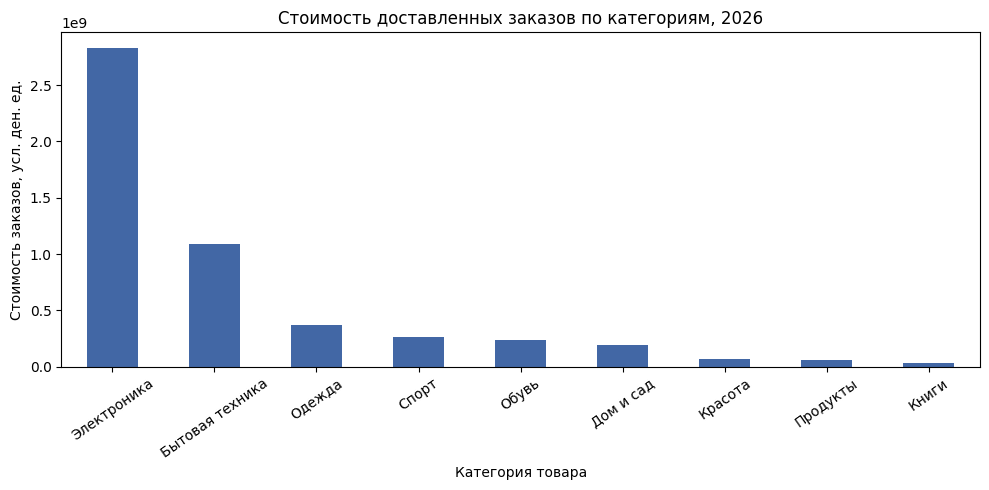

In [14]:
# Шаг 02.14 — График стоимости по категориям
fig, ax = plt.subplots(figsize=(10, 5))
category_value.amount.plot.bar(ax=ax, color='#4267a5')
ax.set(title='Стоимость доставленных заказов по категориям, 2026',
       xlabel='Категория товара', ylabel='Стоимость заказов, усл. ден. ед.')
ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
plt.show()
plt.close(fig)

**Выводы раздела**

Сравнение категорий, городов и сегментов становится понятным, когда абсолютные частоты стоят рядом с долями и средними. Частота заказа не равна числу покупателей, а стоимость заказа не равна цене единицы товара. `crosstab` показала совместное распределение категориальных признаков, `pivot_table` — сумму числовой меры, `pivot` переставил уже агрегированные уникальные сочетания, `melt` вернул широкую таблицу в длинную форму. Это разные действия, хотя их результат может иметь похожие заголовки. Проверки итогов особенно полезны при переходе между ними: сумма доставленной стоимости должна сохраниться после изменения формы и группировки. График помогает увидеть порядок величин, но его заголовок и оси должны сохранять точное определение меры. Интерпретация различий ограничена синтетическим характером набора.

## 3. Календарные месяцы и динамика

Временные операции требуют настоящего типа даты и явного определения момента события. В таблице известна дата оформления заказа, но нет даты фактической доставки. Поэтому месячная стоимость delivered будет группироваться по месяцу оформления тех заказов, чей итоговый статус delivered. Параллельно рассчитывается число всех оформленных заказов; эти два столбца имеют разные единицы и не должны сливаться в один показатель.

**Месячные агрегаты через resample**

`resample('MS')` группирует datetime-индекс по месяцам, помеченным первым числом. Число заказов рассчитывается по всем статусам, а стоимость — только на delivered-выборке. У обоих рядов месяц определяется датой оформления `order_ts`. Поскольку дата доставки отсутствует, полученный денежный ряд не следует называть поступлениями в месяце доставки. Таблица объединяет показатели рядом ради сравнения формы динамики, но не смешивает их арифметически: одна колонка измерена заказами, другая денежной стоимостью.

In [15]:
# Шаг 02.15 — Месячные агрегаты через resample
monthly_orders = orders.set_index('order_ts').resample('MS').order_id.size()
monthly_delivered = delivered.set_index('order_ts').resample('MS').amount.sum()
monthly = pd.DataFrame({'all_orders': monthly_orders,
                        'delivered_amount': monthly_delivered})
display(monthly)

,all_orders,delivered_amount
order_ts,,
2026-01-01,19643,510946280
2026-02-01,17248,447699230
2026-03-01,19247,491398620
2026-04-01,18496,478032930
2026-05-01,19480,509299370
2026-06-01,18732,488061590
2026-07-01,19188,483295600
2026-08-01,19271,497332260
2026-09-01,18651,466160820


**Полная календарная сетка через reindex**

`reindex` задаёт ожидаемые двенадцать месяцев года даже тогда, когда в исходной агрегации какой-то месяц отсутствовал бы. В наблюдаемом календарном месяце без событий число заказов равно нулю; здесь `fill_value=0` отражает этот смысл. Но нулём нельзя заполнять месяцы за пределами периода наблюдения. Позднее в когортной матрице будущий месяц будет отмечен `NaN`, потому что отсутствие будущих данных не означает отсутствие повторных покупок. Проверка длины и нулевых месяцев показывает, как именно выровнен ряд.

In [16]:
# Шаг 02.16 — Полная календарная сетка через reindex
calendar_months = pd.date_range('2026-01-01', '2026-12-01', freq='MS')
monthly = monthly.reindex(calendar_months, fill_value=0)
monthly.index.name = 'order_month'
print('Месяцев:', len(monthly), 'нулевых по заказам:', monthly.all_orders.eq(0).sum())
display(monthly.head(4))

Месяцев: 12 нулевых по заказам: 0


,all_orders,delivered_amount
order_month,,
2026-01-01,19643,510946280
2026-02-01,17248,447699230
2026-03-01,19247,491398620
2026-04-01,18496,478032930


**Скользящее среднее трёх месяцев**

Окно `rolling(window=3)` включает текущий и два предыдущих месяца. `min_periods=3` требует полного окна, поэтому у января и февраля результата нет. Это предотвращает сравнение среднего одного месяца со средним трёх месяцев под одним названием. Скользящее среднее сглаживает отдельные скачки, но может отставать от резкого изменения. Здесь усредняется стоимость доставленных заказов по месяцам оформления. Для прогноза на начало месяца текущая месячная сумма была бы ещё неизвестна, поэтому такое значение нельзя переносить в признаки без сдвига.

In [17]:
# Шаг 02.17 — Скользящее среднее трёх месяцев
monthly['delivered_3m_mean'] = monthly.delivered_amount.rolling(
    window=3, min_periods=3).mean()
display(monthly[['delivered_amount', 'delivered_3m_mean']])

,delivered_amount,delivered_3m_mean
order_month,,
2026-01-01,510946280,NaN
2026-02-01,447699230,NaN
2026-03-01,491398620,4.833480e+08
2026-04-01,478032930,4.723769e+08
2026-05-01,509299370,4.929103e+08
2026-06-01,488061590,4.917980e+08
2026-07-01,483295600,4.935522e+08
2026-08-01,497332260,4.895632e+08
2026-09-01,466160820,4.822629e+08


**Сдвиг и месячный темп**

`shift(1)` размещает значение предыдущего месяца в строке текущего. `pct_change()` вычисляет отношение текущего значения к предыдущему минус единица; после умножения на сто получается процентное изменение. У января базы сравнения в этом годовом окне нет, поэтому результат пустой. Если предыдущая сумма нулевая, обычный процент изменения не определён; отдельная проверка показывает, есть ли такие случаи. Положительное значение означает рост к предыдущему месяцу, отрицательное — снижение, но причина по одному ряду не установлена.

In [18]:
# Шаг 02.18 — Сдвиг и месячный темп
monthly['previous_amount'] = monthly.delivered_amount.shift(1)
monthly['change_pct'] = monthly.delivered_amount.pct_change(fill_method=None) * 100
display(monthly[['delivered_amount', 'previous_amount', 'change_pct']].round(2))
print('Нулевых предыдущих сумм:', monthly.previous_amount.eq(0).sum())

,delivered_amount,previous_amount,change_pct
order_month,,,
2026-01-01,510946280,NaN,NaN
2026-02-01,447699230,510946280.0,-12.38
2026-03-01,491398620,447699230.0,9.76
2026-04-01,478032930,491398620.0,-2.72
2026-05-01,509299370,478032930.0,6.54
2026-06-01,488061590,509299370.0,-4.17
2026-07-01,483295600,488061590.0,-0.98
2026-08-01,497332260,483295600.0,2.90
2026-09-01,466160820,497332260.0,-6.27


Нулевых предыдущих сумм: 0


**График ряда и сглаживания**

На одной оси можно сопоставить месячную стоимость и её скользящее среднее: обе линии измерены в одной денежной единице и построены на одном delivered-фильтре. Подписи должны уточнять момент события — месяц оформления. Начало линии среднего после первых двух месяцев соответствует требованию полного окна. Диаграмма показывает эффект сглаживания, но не устанавливает сезонность. Явные `show` и `close` делают вывод ноутбука однозначным и предотвращают повторное отображение фигуры.

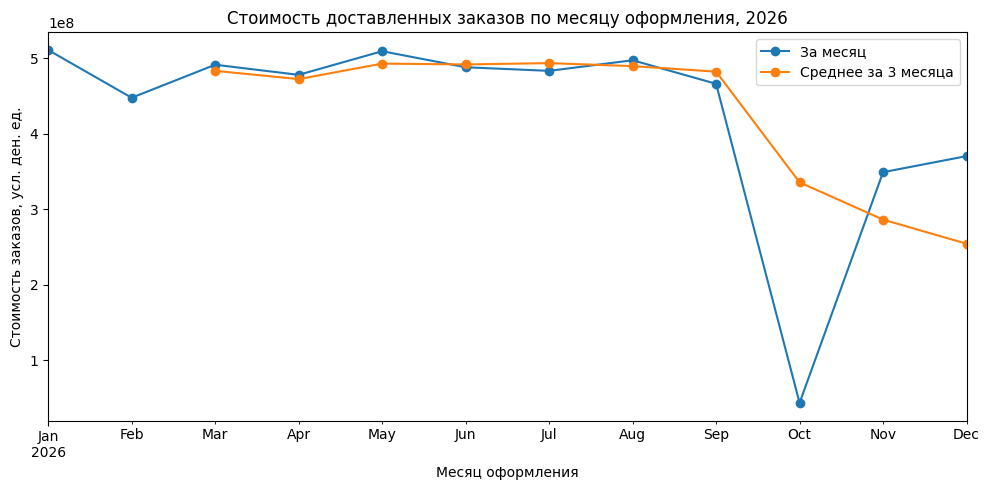

In [19]:
# Шаг 02.19 — График ряда и сглаживания
fig, ax = plt.subplots(figsize=(10, 5))
monthly.delivered_amount.plot(ax=ax, marker='o', label='За месяц')
monthly.delivered_3m_mean.plot(ax=ax, marker='o', label='Среднее за 3 месяца')
ax.set(title='Стоимость доставленных заказов по месяцу оформления, 2026',
       xlabel='Месяц оформления', ylabel='Стоимость заказов, усл. ден. ед.')
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

**Месячные доли категорий**

Группировка по месяцу и категории даёт сумму доставленных заказов каждой категории в каждом месяце. `unstack` переносит категории в столбцы. Деление всей строки на её сумму превращает денежные величины в процентную структуру месяца. Такая доля отвечает на вопрос о месте категории в данном месяце, но не о росте её абсолютной суммы: доля может снизиться даже при росте стоимости категории, если остальные выросли быстрее. Сумма каждой месячной строки должна быть равна ста процентам.

In [20]:
# Шаг 02.20 — Месячные доли категорий
monthly_category = (delivered.assign(
    order_month=delivered.order_ts.dt.to_period('M').dt.to_timestamp())
    .groupby(['order_month', 'category']).amount.sum()
    .unstack(fill_value=0).reindex(calendar_months, fill_value=0))
monthly_category_share = monthly_category.div(monthly_category.sum(axis=1), axis=0) * 100
display(monthly_category_share.round(2))
print('Суммы строк, %:', monthly_category_share.sum(axis=1).round(6).to_list())

category,Бытовая техника,Дом и сад,Книги,Красота,Обувь,Одежда,Продукты,Спорт,Электроника
order_month,,,,,,,,,
2026-01-01,20.15,3.50,0.55,1.26,4.61,6.97,1.10,5.31,56.55
2026-02-01,21.22,3.70,0.56,1.44,4.44,7.15,1.15,4.91,55.41
2026-03-01,22.26,3.66,0.57,1.37,4.60,7.27,1.12,5.20,53.95
2026-04-01,21.92,3.67,0.52,1.26,4.56,7.00,1.18,5.28,54.61
2026-05-01,20.75,3.64,0.52,1.32,4.81,7.05,1.10,5.52,55.28
2026-06-01,21.86,3.54,0.57,1.24,4.55,7.23,1.06,5.23,54.73
2026-07-01,21.84,3.94,0.56,1.33,4.65,7.07,1.23,5.12,54.25
2026-08-01,19.93,3.82,0.54,1.35,4.46,7.32,1.18,5.20,56.20
2026-09-01,21.10,3.72,0.60,1.28,5.08,7.33,1.20,4.58,55.12


Суммы строк, %: [100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0]


**Выводы раздела**

Месячные операции привязаны к `order_ts`, то есть к оформлению заказа. В наборе нет даты фактической доставки, поэтому вычисленная по delivered сумма за месяц не означает денежное поступление в этом месяце. `resample` собрал наблюдения по календарю, `reindex` зафиксировал полную сетку из двенадцати месяцев, `rolling` сгладил три соседних месяца, `shift` и `pct_change` сравнили каждый месяц с предыдущим. Пустые значения первых окон и первой базы сравнения не являются ошибкой данных. При дальнейшем прогнозировании текущий месячный итог был бы неизвестен в начале месяца: его нельзя включать в признаки без временной отсечки. Один синтетический год позволяет освоить операции, но не доказать устойчивую сезонность.

## 4. Покупатели и RFM

Теперь единица наблюдения меняется с заказа на покупателя. Несколько доставленных заказов одного человека сворачиваются в одну строку. RFM описывает давность последней доставленной покупки, количество доставленных заказов и их суммарную стоимость. Дата наблюдения фиксируется сразу после конца синтетического года, чтобы повторный запуск позже не менял результаты. Покупатели без доставленных заказов в этом варианте RFM не участвуют.

**История по каждому покупателю**

Группировка по `customer_id` строит строку на человека. Последняя дата определяется максимумом `order_ts`, частота — числом delivered-заказов, денежная величина — их суммой. Число строк результата должно совпасть с количеством уникальных покупателей в delivered-выборке. Это не все зарегистрированные покупатели из справочника: человек с только отменёнными заказами не имеет последней доставленной покупки. Отдельная популяция нужна для анализа конверсии, но не должна молча попадать в RFM с вымышленной датой.

In [21]:
# Шаг 02.21 — История по каждому покупателю
buyer_history = (delivered.groupby('customer_id')
    .agg(last_order=('order_ts', 'max'),
         frequency=('order_id', 'size'), monetary=('amount', 'sum')))
print('Покупателей с доставкой:', len(buyer_history),
      'уникальных в заказах:', delivered.customer_id.nunique())
display(buyer_history.head())

Покупателей с доставкой: 18517 уникальных в заказах: 18517


,last_order,frequency,monetary
customer_id,,,
1,2026-05-20 18:25:23,3,462010
2,2026-11-20 15:01:20,7,148290
3,2026-11-03 01:11:17,15,348240
4,2026-09-17 05:00:13,4,259990
5,2026-01-30 05:21:23,1,62400


**Фиксированная давность покупки**

Датой наблюдения выбрано 1 января 2027 года, сразу после завершения файла. Recency — целое число дней от последней доставленной покупки до этой даты; чем оно меньше, тем покупка недавнее. Использование системного «сегодня» сделало бы учебный результат зависимым от даты запуска. Дата наблюдения должна быть позднее использованных событий. Проверка отрицательных значений помогает обнаружить нарушение этого условия. Описательная таблица показывает масштабы трёх разных величин: дни, заказы и стоимость.

In [22]:
# Шаг 02.22 — Фиксированная давность покупки
observation_date = pd.Timestamp('2027-01-01')
rfm = buyer_history.copy()
rfm['recency_days'] = (observation_date - rfm.last_order).dt.days
display(rfm[['recency_days', 'frequency', 'monetary']].describe().round(2))
print('Отрицательная давность:', rfm.recency_days.lt(0).sum())

,recency_days,frequency,monetary
count,18517.00,18517.00,1.851700e+04
mean,110.61,8.86,2.773385e+05
std,93.21,184.00,5.745430e+06
min,0.00,1.00,9.000000e+01
25%,27.00,2.00,2.471000e+04
50%,101.00,3.00,8.408000e+04
75%,169.00,6.00,2.005900e+05
max,364.00,21606.00,6.682363e+08


Отрицательная давность: 0


**Объяснимые пороги вместо разрыва связей qcut**

Квантильное деление частоты может столкнуться с множеством одинаковых значений. Приём `rank(method='first')` искусственно раздаёт одинаковым покупателям разные ранги в зависимости от порядка строк. Здесь пороги имеют явный смысл: покупка не старше 30 дней, не меньше десяти доставленных заказов и стоимость не ниже медианы покупателей с доставкой. Денежный порог вычисляется из данных, но одинаковые суммы получают одинаковую метку. Группы не обязаны иметь равный размер; это учебная описательная сегментация, а не оптимизация бизнес-решения.

In [23]:
# Шаг 02.23 — Объяснимые пороги вместо разрыва связей qcut
monetary_threshold = rfm.monetary.median()
rfm['r_group'] = np.where(rfm.recency_days <= 30, 'недавно', 'давно')
rfm['f_group'] = np.where(rfm.frequency >= 10, 'часто', 'реже')
rfm['m_group'] = np.where(rfm.monetary >= monetary_threshold,
                          'не ниже медианы', 'ниже медианы')
print('Порог стоимости:', monetary_threshold)
display(rfm[['r_group', 'f_group', 'm_group']].head())
print('Размеры групп частоты:', rfm.f_group.value_counts().to_dict())

Порог стоимости: 84080.0


,r_group,f_group,m_group
customer_id,,,
1,давно,реже,не ниже медианы
2,давно,реже,не ниже медианы
3,давно,часто,не ниже медианы
4,давно,реже,не ниже медианы
5,давно,реже,ниже медианы


Размеры групп частоты: {'реже': 16372, 'часто': 2145}


**Размеры пересечений R и F**

Кросс-таблица двух групп считает покупателей, поскольку в RFM уже одна строка на человека. Для денежной характеристики пересечения используется медиана стоимости покупателя. Доля пересечения делится на общее число покупателей с delivered-заказом, а не на количество заказов. Третью метку можно использовать как дополнительный фильтр, но полная трёхмерная таблица стала бы менее читаемой. Сегмент здесь описывает наблюдавшееся поведение и может измениться при следующем окне или иной дате расчёта.

In [24]:
# Шаг 02.24 — Размеры пересечений R и F
rf_count = pd.crosstab(rfm.r_group, rfm.f_group)
display(rf_count)
rf_summary = (rfm.groupby(['r_group', 'f_group'])
    .agg(buyers=('monetary', 'size'), median_monetary=('monetary', 'median')))
rf_summary['buyer_share_pct'] = rf_summary.buyers / len(rfm) * 100
display(rf_summary.round(2))

f_group,реже,часто
r_group,,
давно,12980,567
недавно,3392,1578


buyers  median_monetary  buyer_share_pct
r_group f_group                                          
давно   реже      12980          57855.0            70.10
        часто       567         371960.0             3.06
недавно реже       3392         103890.0            18.32
        часто      1578         615740.0             8.52

**Выводы раздела**

RFM меняет уровень анализа с заказов на покупателей и фиксирует дату наблюдения на 1 января 2027 года. В расчёт попали 18 517 человек с хотя бы одной доставленной покупкой в 2026 году. Покупатели без такой покупки здесь отсутствуют, поэтому доли RFM не описывают всю зарегистрированную базу. Recency выражена в днях от последней покупки, frequency — в числе доставленных заказов, monetary — в суммарной стоимости этих заказов. Явные пороги дают одинаковым значениям одинаковые метки и не зависят от порядка строк. Они служат понятной учебной классификацией, а не автоматически оптимальными бизнес-границами. При новом периоде наблюдения те же люди могут перейти в другие группы.

## 5. Когорты первых доставленных покупок

Когорта объединяет покупателей по месяцу первой delivered-покупки, видимой в наборе. Поскольку более ранней истории нет, это первая покупка внутри 2026 года, а не обязательно первая за всю жизнь человека. Удержание на возрасте один месяц означает долю членов когорты, у которых есть хотя бы одна delivered-покупка в следующем календарном месяце. Повторные заказы одного человека внутри месяца не должны увеличивать число активных покупателей.

**Месяц первой видимой доставленной покупки**

Когорта определяется по delivered-заказам, чтобы отменённый заказ не считался состоявшейся покупкой. Месяц заказа превращается в календарную метку начала месяца. `transform('min')` повторяет первый месяц покупателя на каждой его строке, сохраняя длину таблицы. Размер когорты подсчитывается по уникальным покупателям, а не по заказам: несколько delivered-заказов в первый месяц дают одного участника. Сумма размеров всех когорт должна равняться числу покупателей с доставкой из раздела RFM.

In [25]:
# Шаг 02.25 — Месяц первой видимой доставленной покупки
cohort_orders = delivered[['customer_id', 'order_ts', 'order_id']].copy()
cohort_orders['order_month'] = cohort_orders.order_ts.dt.to_period('M').dt.to_timestamp()
cohort_orders['cohort_month'] = cohort_orders.groupby('customer_id').order_month.transform('min')
cohort_size = (cohort_orders[['customer_id', 'cohort_month']].drop_duplicates()
               .groupby('cohort_month').customer_id.size())
display(cohort_size.rename('buyers').to_frame())
print('Всего в когортах:', cohort_size.sum(), 'покупателей RFM:', len(rfm))

,buyers
cohort_month,
2026-01-01,6393
2026-02-01,3124
2026-03-01,2501
2026-04-01,1716
2026-05-01,1405
2026-06-01,958
2026-07-01,760
2026-08-01,616
2026-09-01,466


Всего в когортах: 18517 покупателей RFM: 18517


**Возраст когорты и уникальная активность**

Возраст когорты — число календарных месяцев между месяцем заказа и первым месяцем покупателя. Его удобно вычислять разницей годов и месяцев, получая целое число. Для каждой пары когорта — возраст рассчитывается `nunique(customer_id)`, потому что удержание измеряет людей с хотя бы одной delivered-покупкой, а не количество их заказов. В возрасте ноль активны все участники когорты по определению. Проверка отсутствия отрицательного возраста подтверждает, что первый месяц назначен правильно.

In [26]:
# Шаг 02.26 — Возраст когорты и уникальная активность
cohort_orders['age'] = ((cohort_orders.order_month.dt.year - cohort_orders.cohort_month.dt.year) * 12
                        + cohort_orders.order_month.dt.month - cohort_orders.cohort_month.dt.month)
cohort_active = (cohort_orders.groupby(['cohort_month', 'age'])
                 .customer_id.nunique().unstack())
display(cohort_active.iloc[:, :6])
print('Отрицательных возрастов:', cohort_orders.age.lt(0).sum())

age,0,1,2,3,4,5
cohort_month,,,,,,
2026-01-01,6393.0,2609.0,2741.0,2707.0,2791.0,2723.0
2026-02-01,3124.0,971.0,931.0,1001.0,967.0,995.0
2026-03-01,2501.0,662.0,685.0,686.0,741.0,716.0
2026-04-01,1716.0,445.0,444.0,423.0,426.0,441.0
2026-05-01,1405.0,338.0,335.0,360.0,349.0,29.0
2026-06-01,958.0,213.0,220.0,216.0,29.0,164.0
2026-07-01,760.0,158.0,162.0,15.0,110.0,126.0
2026-08-01,616.0,136.0,10.0,101.0,93.0,NaN
2026-09-01,466.0,9.0,73.0,61.0,NaN,NaN


Отрицательных возрастов: 0


**Матрица удержания с цензурированием**

Знаменатель каждой строки — первоначальный размер когорты, постоянный для всех её возрастов. Месяц возраста доступен, только если он не позже декабря 2026 года. В доступной ячейке без активных покупателей указывается ноль; будущая ячейка помечается `NaN`. Это правое цензурирование окна. Например, для декабрьской когорты возраст один требует января 2027 года и не может оцениваться по этому файлу. Нулевой возраст всех когорт должен дать сто процентов.

In [27]:
# Шаг 02.27 — Матрица удержания с цензурированием
ages = pd.Index(range(12), name='age')
cohort_active = cohort_active.reindex(index=cohort_size.index, columns=ages)
last_month = calendar_months[-1]
months_available = ((last_month.year - cohort_size.index.year) * 12
                    + last_month.month - cohort_size.index.month).to_numpy()
available = pd.DataFrame(np.arange(12)[None, :] <= months_available[:, None],
                         index=cohort_size.index, columns=ages)
cohort_active = cohort_active.fillna(0).where(available)
retention = cohort_active.div(cohort_size, axis=0) * 100
display(retention.round(2))
print('Возраст 0 всегда 100%:', retention[0].eq(100).all())
print('Декабрь, возраст 1 — NaN:', pd.isna(retention.loc[pd.Timestamp('2026-12-01'), 1]))

age,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2026-01-01,100.0,40.81,42.88,42.34,43.66,42.59,42.69,43.05,41.69,7.93,35.57,36.31
2026-02-01,100.0,31.08,29.80,32.04,30.95,31.85,32.20,30.92,3.81,24.17,25.61,NaN
2026-03-01,100.0,26.47,27.39,27.43,29.63,28.63,26.35,2.88,22.51,21.43,NaN,NaN
2026-04-01,100.0,25.93,25.87,24.65,24.83,25.70,3.61,19.00,19.58,NaN,NaN,NaN
2026-05-01,100.0,24.06,23.84,25.62,24.84,2.06,17.65,17.22,NaN,NaN,NaN,NaN
2026-06-01,100.0,22.23,22.96,22.55,3.03,17.12,17.22,NaN,NaN,NaN,NaN,NaN
2026-07-01,100.0,20.79,21.32,1.97,14.47,16.58,NaN,NaN,NaN,NaN,NaN,NaN
2026-08-01,100.0,22.08,1.62,16.40,15.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-01,100.0,1.93,15.67,13.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Возраст 0 всегда 100%: True
Декабрь, возраст 1 — NaN: True


**Одинаковый возраст и разные веса когорт**

Для сопоставимого сравнения используется удержание в возрасте один месяц только у когорт, для которых доступен следующий месяц наблюдения. Декабрь исключается автоматически через `dropna`. Простое среднее процентов даёт одинаковый вес каждой когорте независимо от её размера. Взвешенная доля суммирует активных покупателей всех доступных когорт и делит на сумму их стартовых размеров; она отвечает на вопрос о случайном покупателе объединённой выборки. Два результата могут различаться и оба быть корректными для разных вопросов.

In [28]:
# Шаг 02.28 — Одинаковый возраст и разные веса когорт
age1 = retention[1].dropna()
eligible_sizes = cohort_size.loc[age1.index]
weighted_age1 = cohort_active.loc[age1.index, 1].sum() / eligible_sizes.sum() * 100
print('Доступных когорт:', len(age1))
print('Среднее по когортам, %:', round(age1.mean(), 2))
print('Доля по всем доступным покупателям, %:', round(weighted_age1, 2))
display(age1.rename('retention_pct').round(2).to_frame())

Доступных когорт: 11
Среднее по когортам, %: 22.71
Доля по всем доступным покупателям, %: 30.62


,retention_pct
cohort_month,
2026-01-01,40.81
2026-02-01,31.08
2026-03-01,26.47
2026-04-01,25.93
2026-05-01,24.06
2026-06-01,22.23
2026-07-01,20.79
2026-08-01,22.08
2026-09-01,1.93


**Выводы раздела**

Когортное удержание использует постоянный стартовый размер когорты в знаменателе и уникальных покупателей с повторной доставленной покупкой в числителе. Возраст ноль равен ста процентам по определению. За пределами декабря 2026 года будущая активность неизвестна, поэтому соответствующие ячейки остаются `NaN`; внутри наблюдаемого окна отсутствие повторных покупателей выражается нулём. При сравнении когорт нужно брать одинаковый возраст, иначе ранние когорты получают больше времени на возвращение. Среднее из когортных процентов и доля всех покупателей доступных когорт различаются из-за весов. Наконец, первая видимая покупка в файле не обязательно первая покупка человека за всю жизнь: история до января 2026 года отсутствует.

## 6. Задачи и полностью разобранные решения

Четыре заключительные задачи используют уже рассчитанные таблицы и продолжают ту же последовательность занятия. В каждой сначала сформулирован измеряемый вопрос, затем приведён расчёт и объяснение его границ. Цель — связать синтаксис Pandas с выбором популяции: городские доли считают по заказам или суммам, центр распределения категорий считают по заказам, активность сегмента считают на покупателя, а повторную покупку когорты считают на фиксированном возрасте.

**Задача: две доли города**

Вопрос: какой город лидирует по доле стоимости доставленных заказов и как его денежная доля отличается от доли по количеству? Для первой доли сумма города делится на общую стоимость delivered, для второй число заказов города делится на число delivered-заказов. Разность двух процентов измеряется в процентных пунктах. Положительное значение означает, что денежный вес города выше его веса по количеству заказов, что согласуется с более высоким средним заказом. Это описательное сопоставление, не причинное объяснение.

In [29]:
# Шаг 02.29 — Задача: две доли города
city_task = (delivered.groupby('city')
    .agg(orders=('order_id', 'size'), amount=('amount', 'sum')))
city_task['orders_pct'] = city_task.orders / len(delivered) * 100
city_task['amount_pct'] = city_task.amount / delivered_amount * 100
city_task['gap_pp'] = city_task.amount_pct - city_task.orders_pct
city_task = city_task.sort_values('amount_pct', ascending=False)
display(city_task.round(2))
print('Лидер по доле стоимости:', city_task.index[0])

,orders,amount,orders_pct,amount_pct,gap_pp
city,,,,,
Москва,66516,2076257880,40.54,40.43,-0.11
Новосибирск,17846,582032610,10.88,11.33,0.46
Санкт-Петербург,15918,509258020,9.70,9.92,0.21
Казань,6317,198400470,3.85,3.86,0.01
Самара,6067,192444940,3.70,3.75,0.05
Екатеринбург,6195,190660510,3.78,3.71,-0.06
Красноярск,5881,185672890,3.58,3.62,0.03
Краснодар,5834,177962450,3.56,3.47,-0.09
Тюмень,5636,176485110,3.44,3.44,0.00


Лидер по доле стоимости: Москва


**Задача: средний заказ и медиана категории**

Вопрос: у какой категории самый дорогой средний delivered-заказ и совпадает ли лидер по медиане? Среднее делит сумму заказов категории на их число. Медиана берёт центральное значение упорядоченных сумм и слабее реагирует на единичный дорогой заказ. Число наблюдений показывается для контекста. Это стоимость целого заказа, а не цена одной единицы товара: `amount` учитывает `qty`. Лидер по среднему не обязан быть лидером по суммарной стоимости категории.

In [30]:
# Шаг 02.30 — Задача: средний заказ и медиана категории
category_task = (delivered.groupby('category')
    .agg(orders=('order_id', 'size'), mean_order=('amount', 'mean'),
         median_order=('amount', 'median')).sort_values('mean_order', ascending=False))
display(category_task.round(2))
print('Лидер среднего:', category_task.index[0])
print('Лидер медианы:', category_task.median_order.idxmax())

,orders,mean_order,median_order
category,,,
Электроника,29871,94681.05,76030.0
Бытовая техника,16206,67135.66,56240.0
Спорт,9530,27903.33,22450.0
Дом и сад,9725,19423.14,15780.0
Обувь,16210,14750.55,12170.0
Одежда,33154,11153.97,8730.0
Красота,11247,6027.83,4770.0
Продукты,25509,2321.57,1900.0
Книги,12609,2262.54,1760.0


Лидер среднего: Электроника
Лидер медианы: Электроника


**Задача: активность покупателей сегмента**

Вопрос: в каком сегменте больше delivered-заказов на одного активного покупателя? Активным здесь считается покупатель с хотя бы одним delivered-заказом за 2026 год. Числитель — число заказов сегмента, знаменатель — число уникальных таких покупателей. Отдельная доля сегмента среди активных покупателей делится на общее число покупателей RFM. Это не конверсия всех зарегистрированных людей: для неё нужен знаменатель из всего справочника, включая покупателей без delivered-заказа.

In [31]:
# Шаг 02.31 — Задача: активность покупателей сегмента
segment_task = segment_summary[['orders', 'buyers', 'orders_per_buyer']].copy()
segment_task['active_buyer_pct'] = segment_task.buyers / len(rfm) * 100
segment_task = segment_task.sort_values('orders_per_buyer', ascending=False)
display(segment_task.round(2))
print('Лидер по заказам на активного покупателя:', segment_task.index[0])
print('Сумма долей покупателей, %:', round(segment_task.active_buyer_pct.sum(), 6))

,orders,buyers,orders_per_buyer,active_buyer_pct
segment,,,,
regular,125141,12927,9.68,69.81
vip,11446,1532,7.47,8.27
new,27474,4058,6.77,21.91


Лидер по заказам на активного покупателя: regular
Сумма долей покупателей, %: 100.0


**Задача: повторная покупка через месяц**

Вопрос: как различается удержание возраста один месяц у январской и ноябрьской когорт? Январь сравнивается с февралем, ноябрь с декабрём: расстояние от первого месяца одинаково. Числитель — уникальные покупатели с delivered-покупкой в следующем месяце, знаменатель — исходный размер соответствующей когорты. Разность долей выражается в процентных пунктах. Декабрьскую когорту брать нельзя, поскольку её следующий месяц наступает уже после конца набора. Различие наблюдаемых процентов само по себе не объясняет причину.

In [32]:
# Шаг 02.32 — Задача: повторная покупка через месяц
january, november = pd.Timestamp('2026-01-01'), pd.Timestamp('2026-11-01')
repeat_task = pd.DataFrame({
    'cohort_buyers': cohort_size.loc[[january, november]],
    'next_month_buyers': cohort_active.loc[[january, november], 1].astype(int),
    'next_month_pct': retention.loc[[january, november], 1]})
display(repeat_task.round(2))
print('Январь минус ноябрь, п.п.:',
      round(repeat_task.loc[january, 'next_month_pct'] -
            repeat_task.loc[november, 'next_month_pct'], 2))

,cohort_buyers,next_month_buyers,next_month_pct
cohort_month,,,
2026-01-01,6393,2609,40.81
2026-11-01,308,50,16.23


Январь минус ноябрь, п.п.: 24.58


**Выводы раздела**

Четыре задачи закрепили один общий приём: сперва сформулировать единицу наблюдения и знаменатель, затем выбрать методы Pandas. Городская задача сравнивала долю числа заказов с долей стоимости, категорийная — среднее с медианой, сегментная — заказы с уникальными покупателями, когортная — повторную покупку на одинаковом возрасте. Числовой ответ имеет смысл только вместе с этими условиями. Процентные пункты обозначают разность долей, а не относительный процентный рост. Пример с декабрьской когортой напоминает, что неизвестное будущее нельзя записывать как нулевой результат. Все наблюдаемые различия в этом синтетическом наборе описательные: для причинных выводов и прогноза нужны отдельный дизайн и данные.

**Итог занятия**

Аналитика Pandas начинается с определения единицы наблюдения, фильтра и знаменателя. `groupby`, `agg`, `transform`, частотные и сводные таблицы показывают заказы под разными углами; изменение формы через `pivot` и `melt` не меняет смысл исходной меры. Временные операции требуют календарной сетки и знания границ наблюдения. Для RFM фиксируется дата расчёта, для когорт сохраняется неизвестность будущих месяцев. Полученные величины описывают синтетический набор и демонстрируют метод, а не реальный рынок.